# HerBERT training — side classification (left / center / right)

This notebook:
1. loads splits from `data/term9/splits/`
2. computes (or loads from cache) **allegro/herbert-base-cased** embeddings
3. trains Logistic Regression (`class_weight=balanced`)
4. calibrates the **left** class bias on validation
5. plots class distributions, confusion matrices, and F1 scores
6. saves the model to `models/`

**Note:** the first encoding of ~35k speeches on CPU can take a long time. Embeddings are cached in `data/term9/embeddings/`.

In [4]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
)

# Prefer running from the repo root (where pyproject.toml lives).
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    # Fallback when the kernel starts under notebooks/
    for parent in [ROOT, *ROOT.parents]:
        if (parent / "pyproject.toml").exists():
            ROOT = parent
            break

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from data_mining_project.utils.herbert import (
    DEFAULT_BATCH_SIZE,
    DEFAULT_MAX_LENGTH,
    DEFAULT_MODEL_NAME,
    encode_texts,
    load_herbert,
    resolve_device,
)
from data_mining_project.utils.side_calibration import (
    predict_with_left_bias,
    tune_left_bias,
)

SPLITS_DIR = ROOT / "data" / "term9" / "splits"
EMBEDDINGS_DIR = ROOT / "data" / "term9" / "embeddings"
MODELS_DIR = ROOT / "models"
SIDE_ORDER = ["left", "center", "right"]

print("ROOT:", ROOT)
print("device:", resolve_device())
print("splits exist:", (SPLITS_DIR / "train.csv").exists())

ROOT: c:\Users\miburd\OneDrive - ASSA ABLOY Group\Desktop\private\agh\data-mining-project
device: cpu
splits exist: True


## 1. Data and class distribution

train: 24,111 speeches | members=321
side
left       3909
center    10979
right      9223

val: 7,300 speeches | members=69
side
left      2222
center    3042
right     2036

test: 4,263 speeches | members=69
side
left       799
center    1924
right     1540



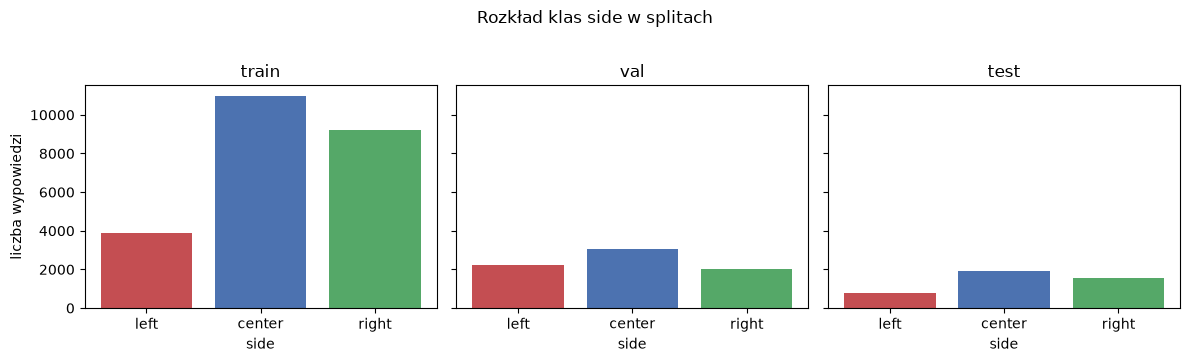

In [2]:
splits = {
    name: pd.read_csv(SPLITS_DIR / f"{name}.csv")
    for name in ("train", "val", "test")
}

for name, df in splits.items():
    print(f"{name}: {len(df):,} speeches | members={df['member_id'].nunique()}")
    print(df["side"].value_counts().reindex(SIDE_ORDER).to_string())
    print()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, name in zip(axes, ("train", "val", "test")):
    counts = splits[name]["side"].value_counts().reindex(SIDE_ORDER)
    ax.bar(counts.index, counts.values, color=["#c44e52", "#4c72b0", "#55a868"])
    ax.set_title(name)
    ax.set_xlabel("side")
axes[0].set_ylabel("number of speeches")
fig.suptitle("Side class distribution across splits", y=1.02)
fig.tight_layout()
plt.show()

## 2. HerBERT embeddings (cache)

If `.npy` files already exist and `meta.json` matches, the cache is loaded.  
Set `RECOMPUTE = True` to recompute embeddings from scratch.

In [ ]:
RECOMPUTE = False
BATCH_SIZE = DEFAULT_BATCH_SIZE  # on GPU you can raise this, e.g. to 32
MAX_LENGTH = DEFAULT_MAX_LENGTH
MODEL_NAME = DEFAULT_MODEL_NAME

EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)
meta_path = EMBEDDINGS_DIR / "meta.json"
expected_meta = {
    "model_name": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "pooling": "mean",
    "n_rows": {name: int(len(splits[name])) for name in ("train", "val", "test")},
}


def cache_ok() -> bool:
    if RECOMPUTE or not meta_path.exists():
        return False
    for name in ("train", "val", "test"):
        if not (EMBEDDINGS_DIR / f"{name}.npy").exists():
            return False
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    return (
        meta.get("model_name") == expected_meta["model_name"]
        and meta.get("max_length") == expected_meta["max_length"]
        and meta.get("pooling") == expected_meta["pooling"]
        and meta.get("n_rows") == expected_meta["n_rows"]
    )


if cache_ok():
    print("Loading embedding cache from", EMBEDDINGS_DIR)
    embeddings = {
        name: np.load(EMBEDDINGS_DIR / f"{name}.npy")
        for name in ("train", "val", "test")
    }
else:
    print("Encoding with HerBERT — this may take a while...")
    tokenizer, encoder, device = load_herbert(MODEL_NAME)
    embeddings = {}
    for name in ("train", "val", "test"):
        print(f"Encoding {name} ({len(splits[name]):,} texts) on {device}...")
        matrix = encode_texts(
            splits[name]["text"].tolist(),
            tokenizer,
            encoder,
            device,
            batch_size=BATCH_SIZE,
            max_length=MAX_LENGTH,
        )
        np.save(EMBEDDINGS_DIR / f"{name}.npy", matrix)
        embeddings[name] = matrix
        print("  shape:", matrix.shape)
    expected_meta["embedding_dim"] = int(embeddings["train"].shape[1])
    meta_path.write_text(json.dumps(expected_meta, indent=2), encoding="utf-8")

for name, matrix in embeddings.items():
    print(f"{name}: {matrix.shape}")

Encoding with HerBERT — this may take a while...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: allegro/herbert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.sso.sso_relationship.weight            | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.sso.sso_relationship.bias              | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding train (24,111 texts) on cpu...


## 3. Train Logistic Regression

In [ ]:
clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    solver="lbfgs",
)
clf.fit(embeddings["train"], splits["train"]["side"])
print("classes:", list(clf.classes_))
print("trained on", embeddings["train"].shape[0], "examples")

## 4. Calibrate left-class bias (on val)

Search for a positive bias on the `left` class probability that maximizes **left F1** on validation.

In [ ]:
from sklearn.metrics import recall_score

biases = np.linspace(0.0, 0.45, 46)
rows = []
for bias in biases:
    y_pred = predict_with_left_bias(clf, embeddings["val"], float(bias))
    left_f1 = f1_score(
        splits["val"]["side"],
        y_pred,
        labels=["left"],
        average="macro",
        zero_division=0,
    )
    macro_f1 = f1_score(
        splits["val"]["side"], y_pred, average="macro", zero_division=0
    )
    recall_left = recall_score(
        splits["val"]["side"],
        y_pred,
        labels=["left"],
        average="macro",
        zero_division=0,
    )
    rows.append(
        {
            "bias": float(bias),
            "left_f1": float(left_f1),
            "macro_f1": float(macro_f1),
            "left_recall": float(recall_left),
        }
    )

curve = pd.DataFrame(rows)
left_bias, best_left_f1, best_macro_f1 = tune_left_bias(
    clf, embeddings["val"], splits["val"]["side"], biases=biases
)
print(
    f"Selected left_bias={left_bias:.3f} | val left_f1={best_left_f1:.3f} | "
    f"val macro_f1={best_macro_f1:.3f}"
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve["bias"], curve["left_f1"], label="left F1")
ax.plot(curve["bias"], curve["macro_f1"], label="macro F1")
ax.plot(curve["bias"], curve["left_recall"], label="left recall", linestyle="--")
ax.axvline(left_bias, color="black", linestyle=":", label=f"selected bias={left_bias:.3f}")
ax.set_xlabel("left bias")
ax.set_ylabel("score")
ax.set_title("Left bias calibration on validation")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## 5. Evaluation: raw vs calibrated

In [ ]:
def evaluate(name: str, y_true, y_pred):
    report = classification_report(y_true, y_pred, digits=3, zero_division=0)
    macro = f1_score(y_true, y_pred, average="macro", zero_division=0)
    acc = float((np.asarray(y_pred) == np.asarray(y_true)).mean())
    print(f"=== {name} | acc={acc:.3f} macro_f1={macro:.3f} ===")
    print(report)
    return {
        "accuracy": acc,
        "macro_f1": float(macro),
        "report": classification_report(
            y_true, y_pred, digits=3, zero_division=0, output_dict=True
        ),
    }


results = {}
for split_name in ("val", "test"):
    y_true = splits[split_name]["side"]
    y_raw = clf.predict(embeddings[split_name])
    y_cal = predict_with_left_bias(clf, embeddings[split_name], left_bias)
    results[split_name] = {
        "raw": evaluate(f"{split_name} RAW", y_true, y_raw),
        "calibrated": evaluate(f"{split_name} CALIBRATED", y_true, y_cal),
        "y_true": y_true,
        "y_raw": y_raw,
        "y_cal": y_cal,
    }

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind, title in zip(
    axes,
    ("y_raw", "y_cal"),
    ("Test — no calibration", f"Test — left_bias={left_bias:.3f}"),
):
    ConfusionMatrixDisplay.from_predictions(
        results["test"]["y_true"],
        results["test"][kind],
        labels=SIDE_ORDER,
        ax=ax,
        colorbar=False,
    )
    ax.set_title(title)
fig.suptitle("Confusion matrix (test)", y=1.02)
fig.tight_layout()
plt.show()

In [ ]:
def f1_per_class(report_dict):
    return [report_dict[label]["f1-score"] for label in SIDE_ORDER]


x = np.arange(len(SIDE_ORDER))
width = 0.35
raw_f1 = f1_per_class(results["test"]["raw"]["report"])
cal_f1 = f1_per_class(results["test"]["calibrated"]["report"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - width / 2, raw_f1, width, label="raw")
ax.bar(x + width / 2, cal_f1, width, label="calibrated")
ax.set_xticks(x)
ax.set_xticklabels(SIDE_ORDER)
ax.set_ylim(0, 1)
ax.set_ylabel("F1")
ax.set_title("Test F1 per class: raw vs calibrated")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
for i, (a, b) in enumerate(zip(raw_f1, cal_f1)):
    ax.text(i - width / 2, a + 0.02, f"{a:.2f}", ha="center", fontsize=9)
    ax.text(i + width / 2, b + 0.02, f"{b:.2f}", ha="center", fontsize=9)
plt.show()

print(
    "left F1 test: "
    f"raw={raw_f1[0]:.3f} -> calibrated={cal_f1[0]:.3f} "
    f"(delta={cal_f1[0] - raw_f1[0]:+.3f})"
)

## 6. Save model

In [ ]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODELS_DIR / "side_model.joblib"
calib_path = MODELS_DIR / "side_calibration.json"
metrics_path = MODELS_DIR / "baseline_metrics.json"

joblib.dump(clf, model_path)
calib_path.write_text(
    json.dumps(
        {
            "left_bias": left_bias,
            "left_label": "left",
            "encoder": MODEL_NAME,
            "max_length": MAX_LENGTH,
        },
        indent=2,
    ),
    encoding="utf-8",
)

metrics = {
    "side": {
        "left_bias": left_bias,
        "calibration": {
            "val_left_f1": round(best_left_f1, 4),
            "val_macro_f1": round(best_macro_f1, 4),
        },
        "val": {
            "raw": results["val"]["raw"],
            "calibrated": results["val"]["calibrated"],
        },
        "test": {
            "raw": results["test"]["raw"],
            "calibrated": results["test"]["calibrated"],
        },
    },
    "encoder": {
        "model_name": MODEL_NAME,
        "max_length": MAX_LENGTH,
        "pooling": "mean",
        "embedding_dim": int(embeddings["train"].shape[1]),
    },
}
# classification_report may contain numpy scalars — coerce via default=float
metrics_path.write_text(
    json.dumps(metrics, indent=2, ensure_ascii=False, default=float),
    encoding="utf-8",
)

print("Saved:")
print(" -", model_path)
print(" -", calib_path)
print(" -", metrics_path)

## 7. Quick predict demo

After saving, you can also use the CLI: `uv run predict-side "..."`.

In [ ]:
demo_texts = [
    "Musimy wzmocnić państwo opiekuńcze, podnieść płacę minimalną i chronić prawa pracownicze.",
    "Potrzebujemy kompromisu w sprawie praworządności i współpracy z Unią Europejską.",
    "Należy obniżyć podatki, ograniczyć biurokrację i bronić tradycyjnych wartości.",
]

tokenizer, encoder, device = load_herbert(MODEL_NAME)
demo_emb = encode_texts(
    demo_texts, tokenizer, encoder, device, batch_size=8, max_length=MAX_LENGTH
)
demo_pred = predict_with_left_bias(clf, demo_emb, left_bias)
demo_proba = clf.predict_proba(demo_emb)

for text, label, proba in zip(demo_texts, demo_pred, demo_proba):
    ranked = sorted(zip(clf.classes_, proba), key=lambda x: x[1], reverse=True)
    print(f"[{label}] {text}")
    print("   ", ", ".join(f"{c}={p:.2f}" for c, p in ranked))
    print()